In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# Creating logistics data
data = {
    "date": pd.date_range(start="2026-11-01", periods=20, freq="D"),
    "origin": ["Chennai", "Mumbai", "Bengaluru", "Delhi", "Hyderabad"] * 4,
    "distance_km": [350, 1400, 570, 1420, 630, 340, 980, 2150, 1500, 710,
                    500, 1150, 350, 1750, 620, 840, 1380, 990, 2100, 560],
    "weight_kg": [4.5, 18.0, 7.2, 22.5, 9.0, 3.8, 14.5, 28.0, 19.2, 11.0,
                  6.5, 16.0, 5.0, 24.0, 8.5, 12.0, 17.5, 13.0, 26.5, 7.8],
    "shipping_cost": [380, 1450, 610, 1820, 740, 340, 1120, 2250, 1580, 890,
                      520, 1290, 410, 1950, 690, 960, 1410, 1050, 2180, 630],
    "delivery_days": [2, 5, 3, 6, 3, 2, 4, 7, 5, 3,
                      2, 4, 2, 6, 3, 4, 5, 4, 7, 3],
    "status": ["Delivered", "Delivered", "Delivered", "Delayed", "Delivered",
               "Delivered", "In Transit", "Delayed", "Delivered", "Delivered",
               "Delivered", "In Transit", "Delivered", "Delayed", "Delivered",
               "In Transit", "Delivered", "Delivered", "Delayed", "Delivered"]
}

df = pd.DataFrame(data)
df.head()

,date,origin,distance_km,weight_kg,shipping_cost,delivery_days,status
0,2026-11-01,Chennai,350,4.5,380,2,Delivered
1,2026-11-02,Mumbai,1400,18.0,1450,5,Delivered
2,2026-11-03,Bengaluru,570,7.2,610,3,Delivered
3,2026-11-04,Delhi,1420,22.5,1820,6,Delayed
4,2026-11-05,Hyderabad,630,9.0,740,3,Delivered


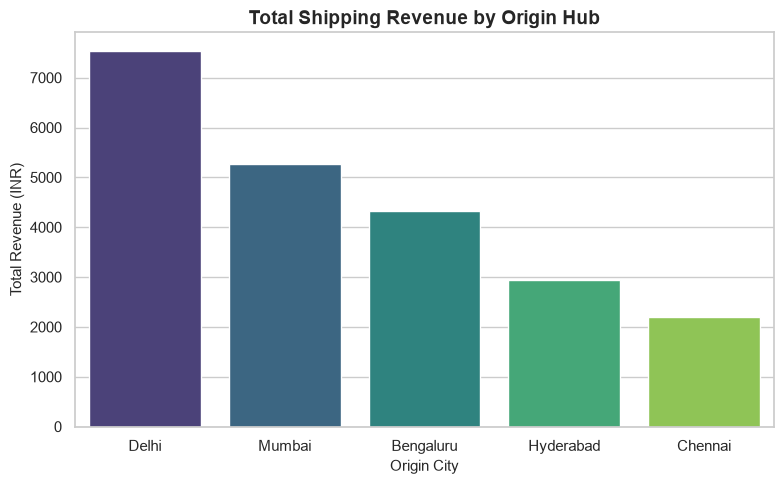

In [2]:
#  BAR CHART: Total Revenue by Origin City
plt.figure(figsize=(8, 5))
hub_revenue = df.groupby("origin", as_index=False)["shipping_cost"].sum().sort_values(by="shipping_cost", ascending=False)

sns.barplot(data=hub_revenue, x="origin", y="shipping_cost", hue="origin", palette="viridis", legend=False)
plt.title("Total Shipping Revenue by Origin Hub", fontsize=14, fontweight="bold")
plt.xlabel("Origin City", fontsize=11)
plt.ylabel("Total Revenue (INR)", fontsize=11)
plt.tight_layout()
plt.show()

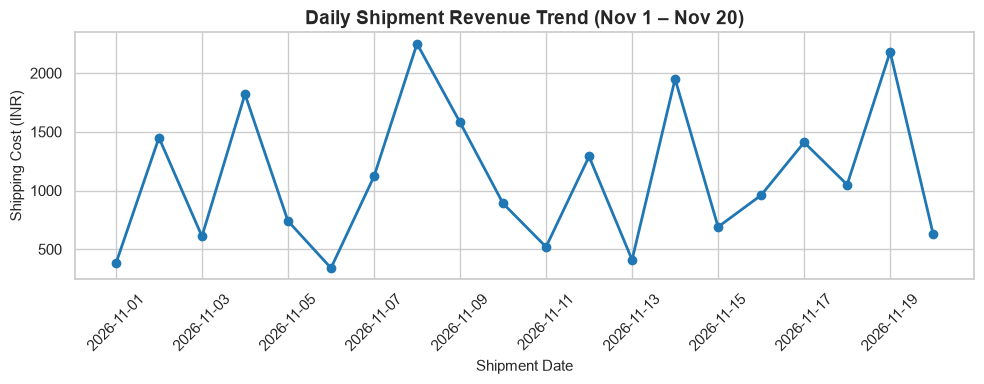

In [3]:
#. LINE CHART: Daily Shipping Cost Trend Over 20 Days
plt.figure(figsize=(10, 4))
plt.plot(df["date"], df["shipping_cost"], marker="o", linestyle="-", color="#1f77b4", linewidth=2)

plt.title("Daily Shipment Revenue Trend (Nov 1 – Nov 20)", fontsize=14, fontweight="bold")
plt.xlabel("Shipment Date", fontsize=11)
plt.ylabel("Shipping Cost (INR)", fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

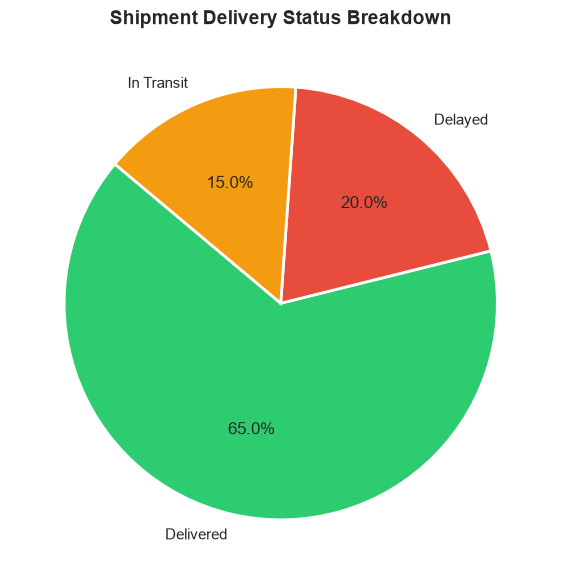

In [4]:
# 3. PIE CHART: Proportion of Shipment Delivery Statuses
status_counts = df["status"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#2ecc71", "#e74c3c", "#f39c12"],
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)
plt.title("Shipment Delivery Status Breakdown", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

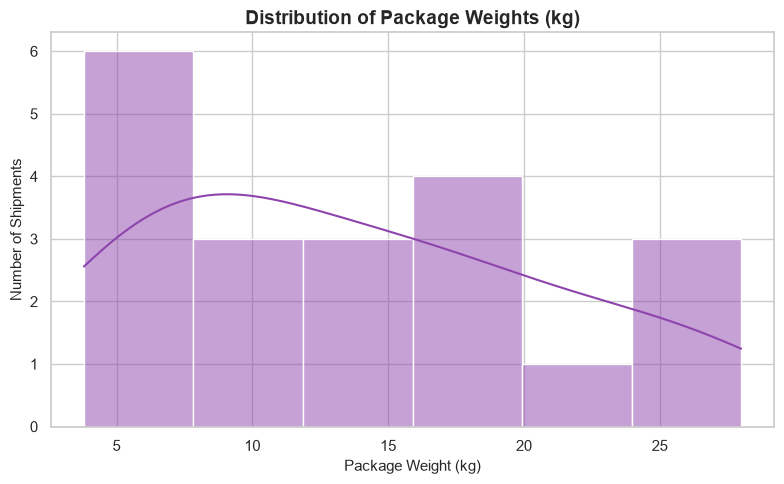

In [5]:
# HISTOGRAM: Distribution of Package Weights
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="weight_kg", bins=6, kde=True, color="#8e44ad")

plt.title("Distribution of Package Weights (kg)", fontsize=14, fontweight="bold")
plt.xlabel("Package Weight (kg)", fontsize=11)
plt.ylabel("Number of Shipments", fontsize=11)
plt.tight_layout()
plt.show()

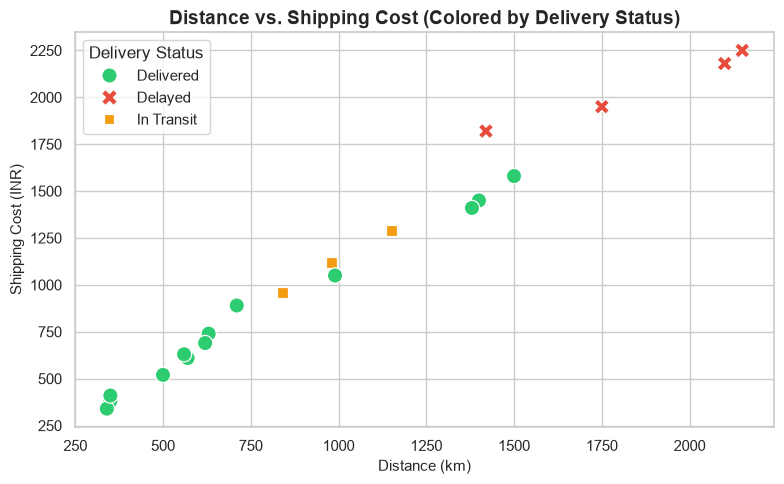

In [6]:
# 5. SCATTER PLOT: Distance vs. Shipping Cost by Delivery Status
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="distance_km",
    y="shipping_cost",
    hue="status",
    style="status",
    s=120,
    palette={"Delivered": "#2ecc71", "Delayed": "#e74c3c", "In Transit": "#f39c12"}
)

plt.title("Distance vs. Shipping Cost (Colored by Delivery Status)", fontsize=14, fontweight="bold")
plt.xlabel("Distance (km)", fontsize=11)
plt.ylabel("Shipping Cost (INR)", fontsize=11)
plt.legend(title="Delivery Status")
plt.tight_layout()
plt.show()